# ANTEX — where does the GNSS antenna actually measure a signal?

The antenna's effective signal reception point is usually not the ARP. A PCO is a vector, commonly given in the local **north–east–up (NEU)** frame. A PCV is an additional direction-dependent correction. ANTEX stores these in **millimetres**; `dsoclasses` returns them in **metres**.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from dsoclasses.gnss.atx import Atx
from os.path import join

data_path = "../../data"
antex = join(data_path, "igs20.atx")
cal = Atx(antex).get_noazi('TRM59800.00', ['G01', 'G02'])

for freq in ('G01', 'G02'):
    print(f'{freq} PCO [N, E, U] in mm:', np.round(1000*cal.pco(freq), 1))
    print(f'{freq} PCV at 30° elevation [mm]:',
          round(1000*cal.pcv_hgt(freq, np.deg2rad(30)), 3))

G01 PCO [N, E, U] in mm: [ 0.7  1.4 89.4]
G01 PCV at 30° elevation [mm]: -6.43
G02 PCO [N, E, U] in mm: [ -0.2   0.  117.8]
G02 PCV at 30° elevation [mm]: -4.23


## 1. Project the PCO along a satellite's line of sight

For azimuth $Az$ and elevation $E$, the unit vector from receiver to satellite in NEU is

$$\mathbf u_{\rm NEU}=(\cos E\cos{Az},\;\cos E\sin{Az},\;\sin E)$$

The projected offset is $\mathbf u\cdot\mathbf{PCO}$. Sign matters: if a signal is observed at the effective antenna centre but the theoretical range is calculated from the ARP, the sign of the applied correction must follow the selected observation convention. For our simple example, the ARP-referenced code correction is `+ PCO_projection + PCV`, consistent with the previous positioning notebook.

In [3]:
azimuth = np.deg2rad(120.0)
elevation = np.deg2rad(30.0)
u_neu = np.array([np.cos(elevation)*np.cos(azimuth),
                  np.cos(elevation)*np.sin(azimuth),
                  np.sin(elevation)])

corr = {}
for freq in ('G01', 'G02'):
    pco_projection = float(np.dot(cal.pco(freq), u_neu))
    pcv = float(cal.pcv_hgt(freq, elevation))
    corr[freq] = pco_projection + pcv
    print(f'{freq}: PCO projection = {1000*pco_projection:+.2f} mm; '
          f'PCV = {1000*pcv:+.2f} mm; total = {1000*corr[freq]:+.2f} mm')

# GPS L1/L2 ionosphere-free coefficients also apply to antenna corrections.
f1, f2 = 1575.42e6, 1227.60e6
alpha = f1**2 / (f1**2-f2**2)
beta = -f2**2 / (f1**2-f2**2)
corr_if = alpha*corr['G01'] + beta*corr['G02']
print(f'Ionosphere-free antenna correction: {1000*corr_if:+.2f} mm')
assert np.isfinite(corr_if)

G01: PCO projection = +45.41 mm; PCV = -6.43 mm; total = +38.98 mm
G02: PCO projection = +58.98 mm; PCV = -4.23 mm; total = +54.75 mm
Ionosphere-free antenna correction: +14.59 mm


## 2. The effect depends on satellite elevation

The offset is a **3D vector**. It does not give the same range correction to every satellite. PCV is also elevation-dependent (and can depend on azimuth for fully calibrated antennas). The current `Atx.get_noazi()` implementation reads azimuth-independent (`NOAZI`) receiver PCV only.

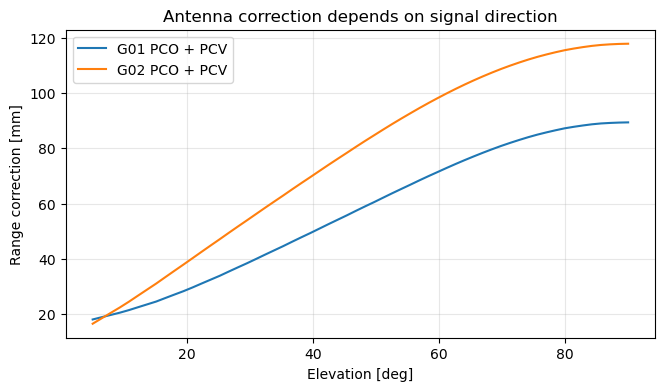

In [4]:
elev_deg = np.linspace(5, 90, 60)
fig, ax = plt.subplots(figsize=(7.6, 4.0))
for freq in ('G01','G02'):
    values=[]
    for deg in elev_deg:
        el = np.deg2rad(deg)
        unit=np.array([np.cos(el)*np.cos(azimuth), np.cos(el)*np.sin(azimuth), np.sin(el)])
        values.append(1000*(np.dot(cal.pco(freq), unit) + cal.pcv_hgt(freq, el)))
    ax.plot(elev_deg, values, label=f'{freq} PCO + PCV')
ax.set(xlabel='Elevation [deg]', ylabel='Range correction [mm]',
       title='Antenna correction depends on signal direction')
ax.grid(alpha=.3)
ax.legend()
plt.show()

### Remember

- ANTEX `G01` and `G02` mean GPS frequency identifiers, **not satellite PRNs**.
- PCO is a vector in **metres** once loaded; PCV is already returned in **metres**. Do **not** multiply PCV by `1e-3` again.
- Select the actual installed antenna model and radome. Satellite antenna calibrations, ARP/marker offsets and sign conventions need separate attention in precise positioning.

Reference: [IGS ANTEX format and standards](https://igs.org/formats-and-standards/).